# 29 — Đối chứng cổ điển: First Fit, BFD, MILP

**T5 • Một development + ba validation • Mỗi input luôn 5 task × 3 host.**

Nhiệm vụ: giải bài toán placement gốc bằng ba phương pháp cổ điển, kiểm tra nghiệm với vét cạn và đọc lại QAOA p=2 từ N27/N28. Không huấn luyện lại QAOA, thay input hoặc đổi thông số để chọn kết quả tốt hơn.

Đọc `N29_README_FIRST.md` trước. Chọn kernel **nt409-khiem**, restart kernel rồi chạy **10 ô mã** theo thứ tự. Ô 1 chỉ kiểm tra môi trường. Nếu thiếu solver, làm theo mục 3 của README rồi restart kernel.

Bảng đối chứng không biến kết quả một lần giải classical thành xác suất 100%; không so mean QUBO energy trực tiếp với số host.

## Ô 1 — Kiểm tra môi trường

Tìm gốc repo và kiểm tra OR-Tools 9.15.6755 / SCIP / một thread. Không tự cài hoặc nâng cấp package. So sánh `Python executable` với terminal khi cần cài dependency.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src/validation5x3.py').is_file()
             and (p / 'experiments/classical_validation.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Mở notebook từ repo đã giải nén gói N29 đúng vị trí.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from experiments import classical_validation as n29
import pandas as pd
import matplotlib.pyplot as plt

print('Repo:', ROOT)
print('Python executable:', sys.executable)
runtime = n29.runtime_preflight()
print(json.dumps(runtime, ensure_ascii=False, indent=2))

Repo: c:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement
Python executable: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
{
  "python": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "packages": {
    "ortools": "9.15.6755",
    "numpy": "2.5.3",
    "pandas": "3.0.6",
    "absl-py": "2.5.1",
    "protobuf": "6.33.6",
    "typing-extensions": "4.16.0",
    "immutabledict": "4.3.1"
  },
  "solver": "SCIP 10.0.0 [LP solver: SoPlex 8.0.0]",
  "threads": 1
}


## Ô 2 — Kiểm tra bằng chứng và mở campaign N29

N27 phải đủ 6 stage; N28 đủ 18 stage. SHA256 kiểm tra dữ liệu và mã đã lưu. Mỗi kết quả QAOA p2 giữ nguyên chi phí p1+p2. N29 lưu bản sao bằng chứng vào ZIP cuối.

Lần đầu có 0/4 case classical; mở lại sẽ giữ các case đã xong. Không xóa N29_ACTIVE để tạo lại một lượt chính.

In [2]:
FOLDER = n29.open_campaign(ROOT)
campaign = n29.checked_campaign(ROOT, FOLDER)
print('Campaign:', FOLDER)
print('Scope: 4 input; mỗi input 5 task × 3 host')
print('Protocol: FirstFit → BFD → MILP; 1 lần/algorithm/case; MILP ≤600 giây, 1 thread')
for label, receipt in campaign['identity']['quantum']['receipts'].items():
    print(label, '| completed stages:', receipt['completed_stages'],
          '| archived objective calls:', receipt['objective_calls'])
print('QAOA p2 rows:', len(campaign['identity']['quantum']['rows']))
print('Classical completed:', n29.summarize(ROOT, FOLDER)['completed_cases'], '/ 4')
display(pd.DataFrame([{'instance_id': c['input']['instance_id'],
                      'tasks': len(c['input']['tasks']), 'hosts': len(c['input']['hosts'])}
                     for c in campaign['identity']['cases']]))

def run_case(instance_id):
    try:
        n29.run_campaign(ROOT, FOLDER, instance_id)
    finally:
        if not (FOLDER / 'RUNNING.lock').exists():
            checkpoint = n29.export_campaign(ROOT, FOLDER)
            print('Checkpoint ZIP:', checkpoint)
    summary = n29.summarize(ROOT, FOLDER)
    rows = [r for r in summary['classical_rows'] if r['instance_id'] == instance_id]
    display(pd.DataFrame(rows)[['algorithm', 'status', 'objective', 'oracle_optimum',
                               'matches_oracle', 'solver_certified_optimal',
                               'solver_bound', 'solver_gap']])
    print('Có thể nghỉ sau ô này. Case đã hoàn tất sẽ không chạy lại.')

Campaign: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase5_classical_validation\t5_20261027T070824197389Z
Scope: 4 input; mỗi input 5 task × 3 host
Protocol: FirstFit → BFD → MILP; 1 lần/algorithm/case; MILP ≤600 giây, 1 thread
N27 | completed stages: 6 | archived objective calls: 570
N28 | completed stages: 18 | archived objective calls: 1564
QAOA p2 rows: 12
Classical completed: 0 / 4


,instance_id,tasks,hosts
0,a3_dev_n5,5,3
1,v5x3_1,5,3
2,v5x3_2,5,3
3,v5x3_3,5,3


## Ô 3 — a3_dev_n5

Development. Optimum tham chiếu: 2 host. Solver không nhận optimum hoặc nghiệm vét cạn làm đầu vào.

In [3]:
run_case('a3_dev_n5')

a3_dev_n5 / FirstFit: solving...
  feasible; objective=3
a3_dev_n5 / BFD: solving...
  feasible; objective=3
a3_dev_n5 / MILP: solving...
  optimal; objective=2
Checkpoint ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase5_classical_validation\t5_20261027T070824197389Z.zip


,algorithm,status,objective,oracle_optimum,matches_oracle,solver_certified_optimal,solver_bound,solver_gap
0,FirstFit,feasible,3,2,False,False,NaN,NaN
1,BFD,feasible,3,2,False,False,NaN,NaN
2,MILP,optimal,2,2,True,True,2.0,0.0


Có thể nghỉ sau ô này. Case đã hoàn tất sẽ không chạy lại.


## Ô 4 — v5x3_1

Validation 1. Optimum tham chiếu: 2 host. Solver không nhận optimum hoặc nghiệm vét cạn làm đầu vào.

In [4]:
run_case('v5x3_1')

v5x3_1 / FirstFit: solving...
  feasible; objective=3
v5x3_1 / BFD: solving...
  feasible; objective=3
v5x3_1 / MILP: solving...
  optimal; objective=2
Checkpoint ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase5_classical_validation\t5_20261027T070824197389Z.zip


,algorithm,status,objective,oracle_optimum,matches_oracle,solver_certified_optimal,solver_bound,solver_gap
0,FirstFit,feasible,3,2,False,False,NaN,NaN
1,BFD,feasible,3,2,False,False,NaN,NaN
2,MILP,optimal,2,2,True,True,2.0,0.0


Có thể nghỉ sau ô này. Case đã hoàn tất sẽ không chạy lại.


## Ô 5 — v5x3_2

Validation 2. Optimum tham chiếu: 3 host. Heuristic không tìm thấy nghiệm vẫn là kết quả hợp lệ cần giữ; input có đúng một assignment khả thi. Solver không nhận optimum hoặc nghiệm vét cạn làm đầu vào.

In [5]:
run_case('v5x3_2')

v5x3_2 / FirstFit: solving...
  no_placement_found; objective=None
v5x3_2 / BFD: solving...
  no_placement_found; objective=None
v5x3_2 / MILP: solving...
  optimal; objective=3
Checkpoint ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase5_classical_validation\t5_20261027T070824197389Z.zip


,algorithm,status,objective,oracle_optimum,matches_oracle,solver_certified_optimal,solver_bound,solver_gap
0,FirstFit,no_placement_found,NaN,3,False,False,NaN,NaN
1,BFD,no_placement_found,NaN,3,False,False,NaN,NaN
2,MILP,optimal,3.0,3,True,True,3.0,0.0


Có thể nghỉ sau ô này. Case đã hoàn tất sẽ không chạy lại.


## Ô 6 — v5x3_3

Validation 3. Optimum tham chiếu: 3 host. Solver không nhận optimum hoặc nghiệm vét cạn làm đầu vào.

In [6]:
run_case('v5x3_3')

v5x3_3 / FirstFit: solving...
  feasible; objective=3
v5x3_3 / BFD: solving...
  feasible; objective=3
v5x3_3 / MILP: solving...
  optimal; objective=3
Checkpoint ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase5_classical_validation\t5_20261027T070824197389Z.zip


,algorithm,status,objective,oracle_optimum,matches_oracle,solver_certified_optimal,solver_bound,solver_gap
0,FirstFit,feasible,3,3,True,False,NaN,NaN
1,BFD,feasible,3,3,True,False,NaN,NaN
2,MILP,optimal,3,3,True,True,3.0,0.0


Có thể nghỉ sau ô này. Case đã hoàn tất sẽ không chạy lại.


## Ô 7 — Đánh giá chất lượng nghiệm cổ điển

MILP dùng $x_{ih},y_h\in\{0,1\}$ và giải:

$$\min\sum_{h=0}^{2}y_h,\qquad \sum_{h=0}^{2}x_{ih}=1,$$
$$\sum_i d_{ir}x_{ih}\le C_{hr}y_h\quad (r\in\{\mathrm{CPU},\mathrm{RAM}\}).$$

15 biến x + 3 biến y = **18 biến nhị phân**, vẫn là bài toán **5 task × 3 host**. Mã QAOA cần 25 qubit do biểu diễn domain-wall và slack.

- `objective`: số host bật của nghiệm hợp lệ.
- `oracle_objective_gap`: số host dư so với vét cạn.
- `matches_oracle=True`: đã tìm đúng optimum tham chiếu.
- `solver_certified_optimal=True`: MILP có trạng thái optimal cùng cận dưới khớp nghiệm và gap=0.

Ví dụ objective=2, bound=1 nghĩa có nghiệm 2 host nhưng chưa có chứng nhận từ solver. Objective=bound=2, gap=0 cùng trạng thái optimal mới đủ để ghi nhận chứng nhận.

In [7]:
summary = n29.summarize(ROOT, FOLDER)
if not summary['complete']:
    raise RuntimeError('Chưa đủ 4 case. Kiểm tra các ô 3–6 trước khi tổng hợp.')
classical = pd.DataFrame(summary['classical_rows'])
quality_columns = ['instance_id', 'algorithm', 'status', 'found_valid', 'objective',
                   'oracle_optimum', 'oracle_objective_gap', 'matches_oracle',
                   'solver_certified_optimal', 'solver_bound', 'solver_gap']
display(classical[quality_columns])
print('Completed cases:', summary['completed_cases'], '/ 4')
print('Recorded algorithm attempts:', summary['solver_attempts'], '/ 12')
print('All four MILP runs certified optimal:', summary['all_milp_certified'])
if not summary['all_milp_certified']:
    print('Giữ kết quả hiện tại để kiểm tra; chưa chốt T5 và không tự chạy lại.')

,instance_id,algorithm,status,found_valid,objective,oracle_optimum,oracle_objective_gap,matches_oracle,solver_certified_optimal,solver_bound,solver_gap
0,a3_dev_n5,FirstFit,feasible,True,3.0,2,1.0,False,False,NaN,NaN
1,a3_dev_n5,BFD,feasible,True,3.0,2,1.0,False,False,NaN,NaN
2,a3_dev_n5,MILP,optimal,True,2.0,2,0.0,True,True,2.0,0.0
3,v5x3_1,FirstFit,feasible,True,3.0,2,1.0,False,False,NaN,NaN
4,v5x3_1,BFD,feasible,True,3.0,2,1.0,False,False,NaN,NaN
5,v5x3_1,MILP,optimal,True,2.0,2,0.0,True,True,2.0,0.0
6,v5x3_2,FirstFit,no_placement_found,False,NaN,3,NaN,False,False,NaN,NaN
7,v5x3_2,BFD,no_placement_found,False,NaN,3,NaN,False,False,NaN,NaN
8,v5x3_2,MILP,optimal,True,3.0,3,0.0,True,True,3.0,0.0
9,v5x3_3,FirstFit,feasible,True,3.0,3,0.0,True,False,NaN,NaN


Completed cases: 4 / 4
Recorded algorithm attempts: 12 / 12
All four MILP runs certified optimal: True


## Ô 8 — Xác suất QAOA và hai đối chứng ngẫu nhiên

Đọc **12 hàng p2** đã có; không tạo thêm lượt tối ưu hóa. `P_opt` là xác suất một phép đo trả về placement tối ưu theo cách chấm đã khóa.

`uniform_encoded`: lấy đều bitstring mã hóa. `random_host_inferred_y`: lấy đều 243 assignment host rồi suy ra y. Hai đối chứng có cách sinh/giải mã khác nhau; nhãn phải giữ nguyên trong báo cáo.

Biểu đồ dùng P_opt chính xác, không phải tỷ lệ từ 1024 shot. Trục đứng biểu diễn phần trăm; **mỗi ô có thang riêng**. So độ cao cột trong cùng một input.

,instance_id,method,P_valid (%),P_opt (%)
0,a3_dev_n5,random_host_inferred_y,37.037037,3.292181
1,a3_dev_n5,standard_x,16.336144,0.836108
2,a3_dev_n5,uniform_encoded,1.196289,0.097656
3,a3_dev_n5,valid_dw,25.617203,1.543284
4,a3_dev_n5,valid_x,7.330222,0.811382
5,v5x3_1,random_host_inferred_y,32.098765,1.646091
6,v5x3_1,standard_x,11.566711,0.278349
7,v5x3_1,uniform_encoded,1.000977,0.048828
8,v5x3_1,valid_dw,21.618602,0.848718
9,v5x3_1,valid_x,7.296463,0.260118


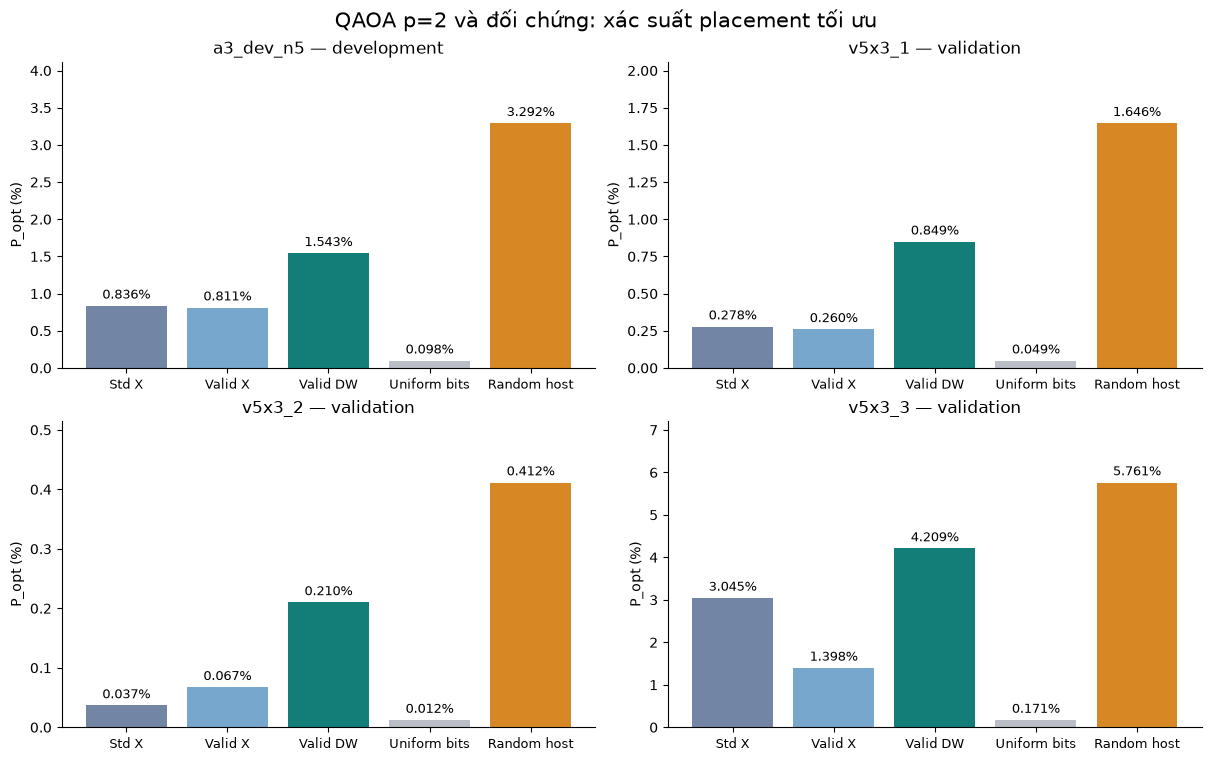

In [8]:
quantum = pd.DataFrame(summary['quantum_rows'])
controls = pd.DataFrame(summary['control_rows'])
q_prob = quantum[['instance_id', 'variant', 'p_valid', 'p_opt']].rename(columns={'variant': 'method'})
probability = pd.concat([q_prob, controls], ignore_index=True)
view = probability.copy()
view['P_valid (%)'] = 100 * view.pop('p_valid')
view['P_opt (%)'] = 100 * view.pop('p_opt')
display(view.sort_values(['instance_id', 'method']).reset_index(drop=True))

methods = ['standard_x', 'valid_x', 'valid_dw', 'uniform_encoded', 'random_host_inferred_y']
labels = ['Std X', 'Valid X', 'Valid DW', 'Uniform bits', 'Random host']
colors = ['#7285a5', '#77a7cc', '#137d78', '#babfc7', '#d78825']
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), constrained_layout=True)
for ax, cid in zip(axes.flat, n29.CASE_IDS):
    row = probability[probability['instance_id'] == cid].set_index('method')
    values = [100 * row.loc[m, 'p_opt'] for m in methods]
    bars = ax.bar(labels, values, color=colors)
    ax.bar_label(bars, labels=[f'{v:.3f}%' for v in values], fontsize=9, padding=3)
    ax.set_ylim(0, max(values) * 1.25)
    ax.set_ylabel('P_opt (%)')
    ax.set_title(cid + (' — development' if cid == 'a3_dev_n5' else ' — validation'))
    ax.tick_params(axis='x', labelsize=9)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('QAOA p=2 và đối chứng: xác suất placement tối ưu', fontsize=15)
figures = FOLDER / 'figures'
figures.mkdir(exist_ok=True)
fig.savefig(figures / 'optimal_probability_p2.png', dpi=180)
fig.savefig(figures / 'optimal_probability_p2.svg')
display(fig)
plt.close(fig)

## Ô 9 — Chi phí thực thi: chỉ mô tả

Mỗi classical algorithm chỉ chạy một lần/case. `build_seconds`, `solve_seconds`, `check_seconds` tách các phần; `total_seconds` loại thời gian import/export. Với QAOA p2, chi phí dưới đây gồm cả p1 để tạo điểm khởi đầu. Runtime gốc của N27/N28 được giữ trong campaign.

Không dùng hai bảng để khẳng định speedup hoặc ưu thế lượng tử: công việc thực hiện và overhead khác nhau, chưa có benchmark thời gian lặp độc lập. Ba input validation mới là cỡ mẫu kiểm chứng; không coi ba nhánh trên mỗi input là ba mẫu độc lập.

In [9]:
print('CLASSICAL — giây, một lần giải/algorithm/case')
display(classical[['instance_id', 'algorithm', 'build_seconds', 'solve_seconds',
                   'check_seconds', 'total_seconds']])
print('QAOA — dữ liệu đã lưu, chi phí huấn luyện p1 + p2')
display(quantum[['instance_id', 'variant', 'training_objective_calls',
                 'training_cap', 'elapsed_stage_seconds', 'source_campaign']])
print('Số lượt optimizer lượng tử mới trong N29: 0')
print(summary['warning'])

CLASSICAL — giây, một lần giải/algorithm/case


,instance_id,algorithm,build_seconds,solve_seconds,check_seconds,total_seconds
0,a3_dev_n5,FirstFit,0.000030,0.000021,0.000172,0.000224
1,a3_dev_n5,BFD,0.000053,0.000136,0.000224,0.000413
2,a3_dev_n5,MILP,0.002074,0.015996,0.000981,0.019051
3,v5x3_1,FirstFit,0.000035,0.000020,0.000181,0.000237
4,v5x3_1,BFD,0.000032,0.000101,0.000204,0.000337
5,v5x3_1,MILP,0.001855,0.005059,0.000300,0.007213
6,v5x3_2,FirstFit,0.000032,0.000021,0.000004,0.000056
7,v5x3_2,BFD,0.000037,0.000091,0.000004,0.000131
8,v5x3_2,MILP,0.001696,0.002357,0.000330,0.004383
9,v5x3_3,FirstFit,0.000031,0.000018,0.000181,0.000231


QAOA — dữ liệu đã lưu, chi phí huấn luyện p1 + p2


,instance_id,variant,training_objective_calls,training_cap,elapsed_stage_seconds,source_campaign
0,a3_dev_n5,standard_x,200,200,1165.433147,N27
1,a3_dev_n5,valid_x,200,200,957.434762,N27
2,a3_dev_n5,valid_dw,170,200,957.329637,N27
3,v5x3_1,standard_x,166,200,942.949606,N28
4,v5x3_1,valid_x,200,200,869.092997,N28
5,v5x3_1,valid_dw,153,200,773.774993,N28
6,v5x3_2,standard_x,200,200,1331.479164,N28
7,v5x3_2,valid_x,162,200,1045.541424,N28
8,v5x3_2,valid_dw,155,200,1513.776494,N28
9,v5x3_3,standard_x,161,200,983.489236,N28


Số lượt optimizer lượng tử mới trong N29: 0
Four fixed 5x3 inputs: one development and three conditioned validation cases. One classical solve per algorithm/case; timings are descriptive, not a speed benchmark. QAOA probabilities describe samples, not classical solver certificates. Random-host control infers y; uniform-encoded control does not. QAOA p2 is primary and its training cost includes p1. No quantum retraining.


## Ô 10 — Xuất và gửi bằng chứng

Bấm **Ctrl+S** sau khi chạy ô cuối. Gửi lại ba file: notebook đã lưu output, ZIP `t5_...zip` dưới đây và `N29_ACTIVE.json`.

ZIP `nt409_notebook29_classical5x3_v1.zip` là gói cài đặt. ZIP `t5_...zip` mới chứa kết quả chạy cần gửi. T5 được chốt sau khi kiểm tra kết quả Windows của bạn; không coi kết quả kiểm thử phần mềm là kết quả đã chạy trên máy bạn.

In [10]:
archive = n29.export_campaign(ROOT, FOLDER)
final_summary = n29.summarize(ROOT, FOLDER)
print('Completed:', final_summary['completed_cases'], '/ 4')
print('Solver attempts:', final_summary['solver_attempts'], '/ 12')
print('MILP certificates:', final_summary['all_milp_certified'])
print('RESULT ZIP:', archive)
print('ZIP SHA256:', n29.file_hash(archive))
print('POINTER:', FOLDER.parent / 'N29_ACTIVE.json')
print('Notebook cần lưu: notebooks/29_classical_baselines_validation.ipynb')
print('Ctrl+S, rồi gửi notebook + RESULT ZIP + POINTER để đánh giá.')

Completed: 4 / 4
Solver attempts: 12 / 12
MILP certificates: True
RESULT ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase5_classical_validation\t5_20261027T070824197389Z.zip
ZIP SHA256: 88da72ae226e8754d263414ca372fa5e2c1ae8267638130ae461b7eb739781e4
POINTER: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase5_classical_validation\N29_ACTIVE.json
Notebook cần lưu: notebooks/29_classical_baselines_validation.ipynb
Ctrl+S, rồi gửi notebook + RESULT ZIP + POINTER để đánh giá.
